In [57]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
import ipywidgets as widgets
import matplotlib.pyplot as plt
import seaborn as sns

In [58]:
PATH = "../data/raw/anemia_dataset.csv"
dataset = pd.read_csv(PATH)

In [59]:
tabela_dimensao = pd.DataFrame({
    "Métrica": ["Linhas (Registros)", "Colunas (Variáveis)"],
    "Quantidade": [dataset.shape[0], dataset.shape[1]],
})

print("\033[32mDimensão:\033[0m")
display(tabela_dimensao)

Dimensão:


,Métrica,Quantidade
0,Linhas (Registros),15300
1,Colunas (Variáveis),29


In [60]:
tabela_info = pd.DataFrame({
    "Coluna": dataset.columns,
    "Não-Nulos": dataset.notnull().sum().values,
    "Nulos": dataset.isnull().sum().values,
    "Tipo (Dtype)": dataset.dtypes.astype(str).values,
    "Valores Únicos": dataset.nunique().values,
})

print("\033[32mInformações adicionais:\033[0m")
display(tabela_info)

Informações adicionais:


,Coluna,Não-Nulos,Nulos,Tipo (Dtype),Valores Únicos
0,GENDER,15300,0,int64,2
1,WBC,15300,0,float64,1736
2,NE#,15300,0,float64,1564
3,LY#,15300,0,float64,848
4,MO#,15300,0,float64,987
5,EO#,15300,0,float64,723
6,BA#,15300,0,float64,374
7,RBC,15300,0,float64,675
8,HGB,15300,0,float64,1226
9,HCT,15300,0,float64,2513


In [61]:
opcoes = ["Todas as colunas"] + dataset.columns.tolist()


@widgets.interact(
    coluna=widgets.Dropdown(
        options=opcoes,
        value="Todas as colunas",
        description="Coluna:",
        layout=widgets.Layout(width="280px"),
    )
)
def ver_estatisticas(coluna):
    if coluna == "Todas as colunas":
        display(dataset.describe().round(2))
    else:
        display(dataset[[coluna]].describe().round(2))

interactive(children=(Dropdown(description='Coluna:', layout=Layout(width='280px'), options=('Todas as colunas…

In [62]:
print("\033[32mPrimeiras linhas:\033[0m")
dataset.head()

Primeiras linhas:


,GENDER,WBC,NE#,LY#,MO#,EO#,BA#,RBC,HGB,HCT,...,SDTSD,TSD,FERRITTE,FOLATE,B12,All_Class,HGB_Anemia_Class,Iron_anemia_Class,Folate_anemia_class,B12_Anemia_class
0,1,10.63,6.31,2.79,0.91,0.56,0.06,4.31,12.7,37.6,...,248.90,40.176778,194.00,5.06,178.2,4,0,0,0,1
1,1,5.08,2.50,1.87,0.43,0.26,0.02,4.34,12.8,36.9,...,348.48,33.482553,57.37,9.88,197.7,4,0,0,0,1
2,1,13.68,9.40,2.69,1.55,0.03,0.01,3.18,9.4,27.5,...,357.27,20.144429,114.20,8.37,143.0,4,0,0,0,1
3,1,5.60,3.94,0.83,0.54,0.26,0.03,3.35,10.5,31.4,...,360.60,27.731559,214.20,6.39,139.9,4,0,0,0,1
4,1,3.57,2.03,1.25,0.10,0.18,0.01,1.31,5.1,14.3,...,223.28,78.860623,303.40,4.30,50.0,4,0,0,0,1


In [63]:
print(f"\033[32mLinhas duplicadas:\033[0m {dataset.duplicated().sum()}")

Linhas duplicadas: 88


## Gráficos de Análise

### Desbalanceamento de Classes

In [64]:
def plotar_distribuicao_coluna(
    df,
    coluna,
    mapa_nomes=None,
    titulo_geral=None,
    xlabel="Categoria",
    ylabel="Quantidade de Pacientes",
    paleta="viridis",
    rotacao_x=15,
):
    serie = df[coluna].map(mapa_nomes) if mapa_nomes else df[coluna]

    contagens = serie.value_counts()
    ordem = contagens.index
    porcentagens = (contagens / contagens.sum()) * 100
    cores = sns.color_palette(paleta, n_colors=len(ordem))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6))

    if titulo_geral:
        fig.suptitle(titulo_geral, fontsize=16, fontweight="bold", y=1.02)

    sns.countplot(
        x=serie,
        hue=serie,
        palette=cores,
        order=ordem,
        legend=False,
        ax=ax1,
    )

    for container in ax1.containers:
        ax1.bar_label(container, padding=3)

    ax1.set_title("Distribuição (Quantidade)", fontsize=14)
    ax1.set_xlabel(xlabel, fontsize=12)
    ax1.set_ylabel(ylabel, fontsize=12)
    ax1.tick_params(axis="x", rotation=rotacao_x)

    wedges, _ = ax2.pie(
        contagens.values,
        colors=cores,
        startangle=90,
        counterclock=False,
        wedgeprops={"width": 0.4, "edgecolor": "white", "linewidth": 2},
    )

    posicoes_y_usadas = []

    for i, wedge in enumerate(wedges):
        angulo = np.deg2rad((wedge.theta2 + wedge.theta1) / 2.0)
        x = np.cos(angulo)
        y = np.sin(angulo)

        lado = 1 if x >= 0 else -1
        alinhamento = "left" if lado == 1 else "right"

        x_texto = 1.35 * lado
        y_texto = 1.15 * y

        for y_ant, lado_ant in posicoes_y_usadas:
            if lado == lado_ant and abs(y_texto - y_ant) < 0.16:
                y_texto = y_ant + (0.16 if y_texto >= y_ant else -0.16)

        posicoes_y_usadas.append((y_texto, lado))

        texto = f"{ordem[i]} ({porcentagens.iloc[i]:.1f}%)"

        ax2.annotate(
            texto,
            xy=(x, y),
            xytext=(x_texto, y_texto),
            ha=alinhamento,
            va="center",
            fontsize=10,
            fontweight="bold",
            color="#333333",
            arrowprops=dict(
                arrowstyle="-",
                color=cores[i],
                lw=1.5,
                connectionstyle="angle,angleA=0,angleB=90,rad=5",
            ),
        )

    ax2.set_xlim(-2.0, 2.2)
    ax2.set_ylim(-1.4, 1.4)
    ax2.set_title("Proporção (%)", fontsize=14, pad=20)

    plt.tight_layout()
    plt.show()

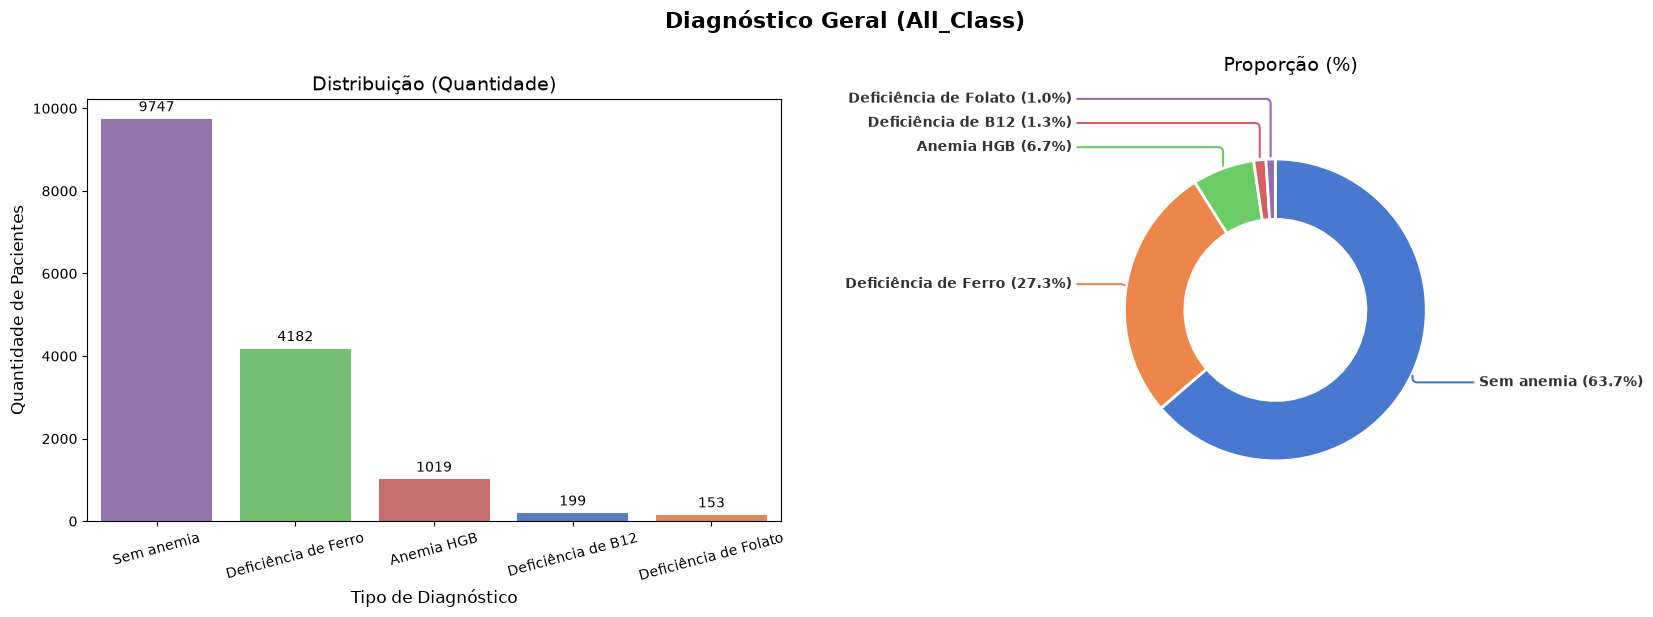

In [65]:
nomes_all_class = {
    0: "Sem anemia",
    1: "Anemia HGB",
    2: "Deficiência de Ferro",
    3: "Deficiência de Folato",
    4: "Deficiência de B12",
}

plotar_distribuicao_coluna(
    dataset,
    coluna="All_Class",
    mapa_nomes=nomes_all_class,
    titulo_geral="Diagnóstico Geral (All_Class)",
    xlabel="Tipo de Diagnóstico",
    paleta="muted"
)

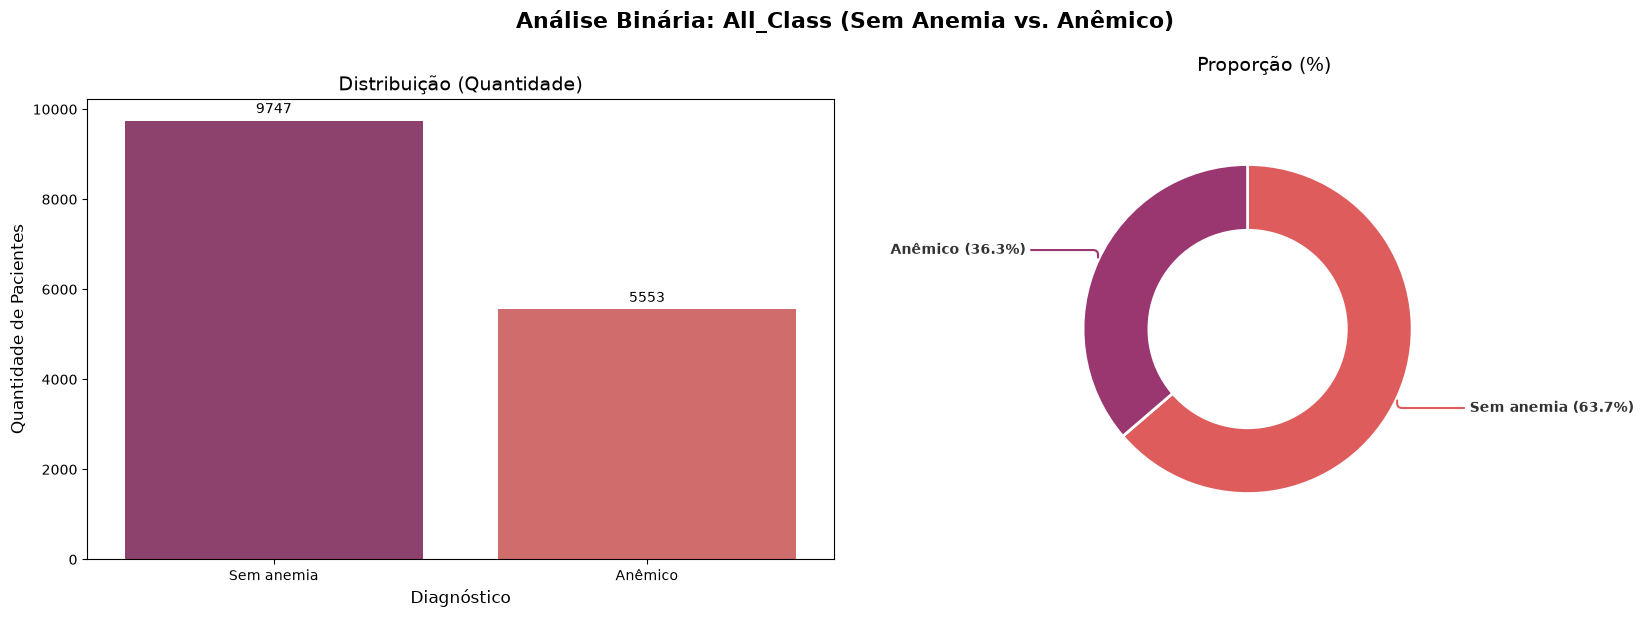

In [66]:
dicionario_all_class = {
    0: "Sem anemia",
    1: "Anêmico",
    2: "Anêmico",
    3: "Anêmico",
    4: "Anêmico",
}

plotar_distribuicao_coluna(
    dataset,
    coluna="All_Class",
    mapa_nomes=dicionario_all_class,
    titulo_geral="Análise Binária: All_Class (Sem Anemia vs. Anêmico)",
    xlabel="Diagnóstico",
    rotacao_x=0,
    paleta="flare",
)


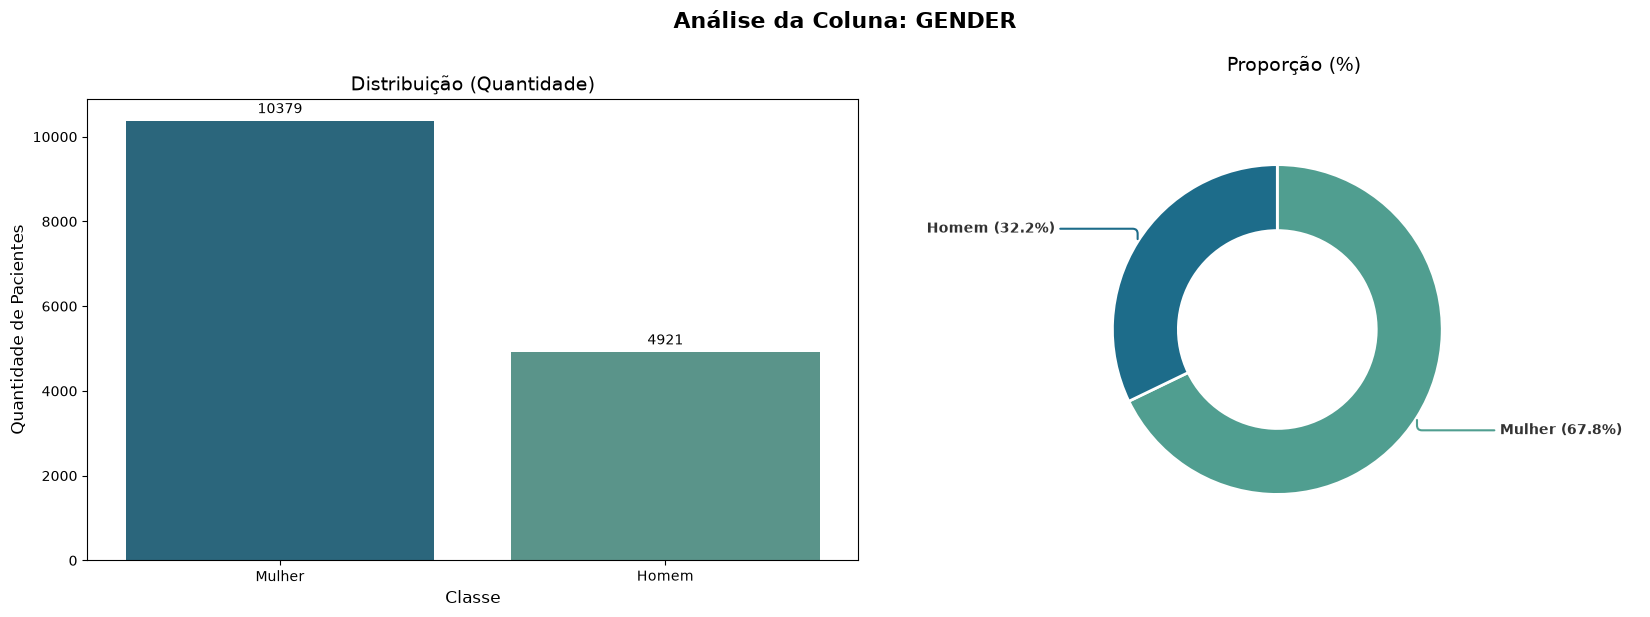

In [67]:
dicionario_gender = {
    0: "Mulher",
    1: "Homem",
}

plotar_distribuicao_coluna(
    dataset,
    coluna="GENDER",
    mapa_nomes=dicionario_gender,
    titulo_geral="Análise da Coluna: GENDER",
    xlabel="Classe",
    rotacao_x=0,
    paleta="crest"
)

In [68]:
cols = dataset.columns.tolist()


def calcular_limites(col):
    Q1 = dataset[col].quantile(0.25)
    Q3 = dataset[col].quantile(0.75)
    IQR = Q3 - Q1
    return (Q1 - 1.5 * IQR, Q3 + 1.5 * IQR)


limites_dict = {col: calcular_limites(col) for col in cols}


def resumir_coluna(col):
    limite_inf, limite_sup = limites_dict[col]
    qtd_outliers = (
        (dataset[col] < limite_inf) | (dataset[col] > limite_sup)
    ).sum()
    pct_outliers = (qtd_outliers / len(dataset)) * 100

    return {
        "Exame": col,
        "Mínimo Real": round(dataset[col].min(), 2),
        "Limite Inferior (IQR)": round(limite_inf, 2),
        "Mediana": round(dataset[col].median(), 2),
        "Limite Superior (IQR)": round(limite_sup, 2),
        "Máximo Real": round(dataset[col].max(), 2),
        "Total Outliers": qtd_outliers,
        "% Outliers": round(pct_outliers, 1),
    }


geral = (
    pd.DataFrame([resumir_coluna(c) for c in cols])
    .sort_values("% Outliers", ascending=False)
    .reset_index(drop=True)
)

mascara_outliers = pd.DataFrame(
    {
        col: (dataset[col] < limites_dict[col][0])
        | (dataset[col] > limites_dict[col][1])
        for col in cols
    },
    index=dataset.index,
)

linhas_com_outlier = mascara_outliers.any(axis=1).sum()
pct_linhas = (linhas_com_outlier / len(dataset)) * 100

display(
    Markdown(
        f"**Linhas com pelo menos 1 outlier:** `{linhas_com_outlier}` de `{len(dataset)}` ({pct_linhas:.1f}%)"
    )
)


def plotar_exame(col, tipo_grafico):
    dados_col = resumir_coluna(col)

    limite_inf, limite_sup = limites_dict[col]
    qtd_outliers = dados_col["Total Outliers"]
    pct_outliers = dados_col["% Outliers"]

    fig, ax = plt.subplots(figsize=(10, 3.5))

    if tipo_grafico == "Boxplot":
        sns.boxplot(
            data=dataset,
            x=col,
            ax=ax,
            color="#4C72B0",
            flierprops=dict(marker="o", markerfacecolor="red", markersize=5),
        )
    elif tipo_grafico == "Histograma + KDE":
        sns.histplot(
            data=dataset,
            x=col,
            kde=True,
            ax=ax,
            color="#4C72B0",
        )
    elif tipo_grafico == "Violin Plot":
        sns.violinplot(
            data=dataset,
            x=col,
            ax=ax,
            color="#4C72B0",
        )

    ax.axvline(
        limite_inf,
        color="red",
        linestyle="--",
        alpha=0.7,
        label=f"Limite Inf: {limite_inf:.2f}",
    )
    ax.axvline(
        limite_sup,
        color="red",
        linestyle="--",
        alpha=0.7,
        label=f"Limite Sup: {limite_sup:.2f}",
    )

    ax.set_title(
        f"{tipo_grafico} - {col} ({qtd_outliers} outliers | {pct_outliers:.1f}%)",
        fontsize=12,
        fontweight="bold",
    )
    ax.set_xlabel(col, fontsize=10)
    ax.legend(loc="upper right")

    plt.tight_layout()
    plt.show()

    display(pd.DataFrame([dados_col]))


cols_ordenadas = geral["Exame"].tolist()

seletor_exame = widgets.Dropdown(
    options=cols_ordenadas, value=cols_ordenadas[0], description="Exame:"
)
seletor_grafico = widgets.Dropdown(
    options=["Boxplot", "Histograma + KDE", "Violin Plot"],
    value="Boxplot",
    description="Gráfico:",
)

painel_controles = widgets.HBox([seletor_exame, seletor_grafico])

out = widgets.interactive_output(
    plotar_exame, {"col": seletor_exame, "tipo_grafico": seletor_grafico}
)

display(painel_controles, out)
display(geral)

**Linhas com pelo menos 1 outlier:** `6620` de `15300` (43.3%)

Output()

,Exame,Mínimo Real,Limite Inferior (IQR),Mediana,Limite Superior (IQR),Máximo Real,Total Outliers,% Outliers
0,FERRITTE,0.50,-124.11,40.20,244.70,27332.00,1690,11.0
1,B12,30.00,-71.05,308.30,732.55,33880.00,1101,7.2
2,HGB_Anemia_Class,0.00,0.00,0.00,0.00,1.00,1019,6.7
3,MCH,12.55,20.75,27.96,34.59,139.00,870,5.7
4,NE#,0.03,-0.32,4.42,9.60,197.20,863,5.6
5,MCV,49.93,67.81,84.40,100.05,125.30,837,5.5
6,EO#,0.00,-0.15,0.12,0.41,9.41,754,4.9
7,FOLATE,0.55,-0.23,7.99,16.73,50.25,697,4.6
8,WBC,0.57,1.42,7.49,13.90,246.70,639,4.2
9,MO#,0.00,0.02,0.53,1.06,18.51,562,3.7


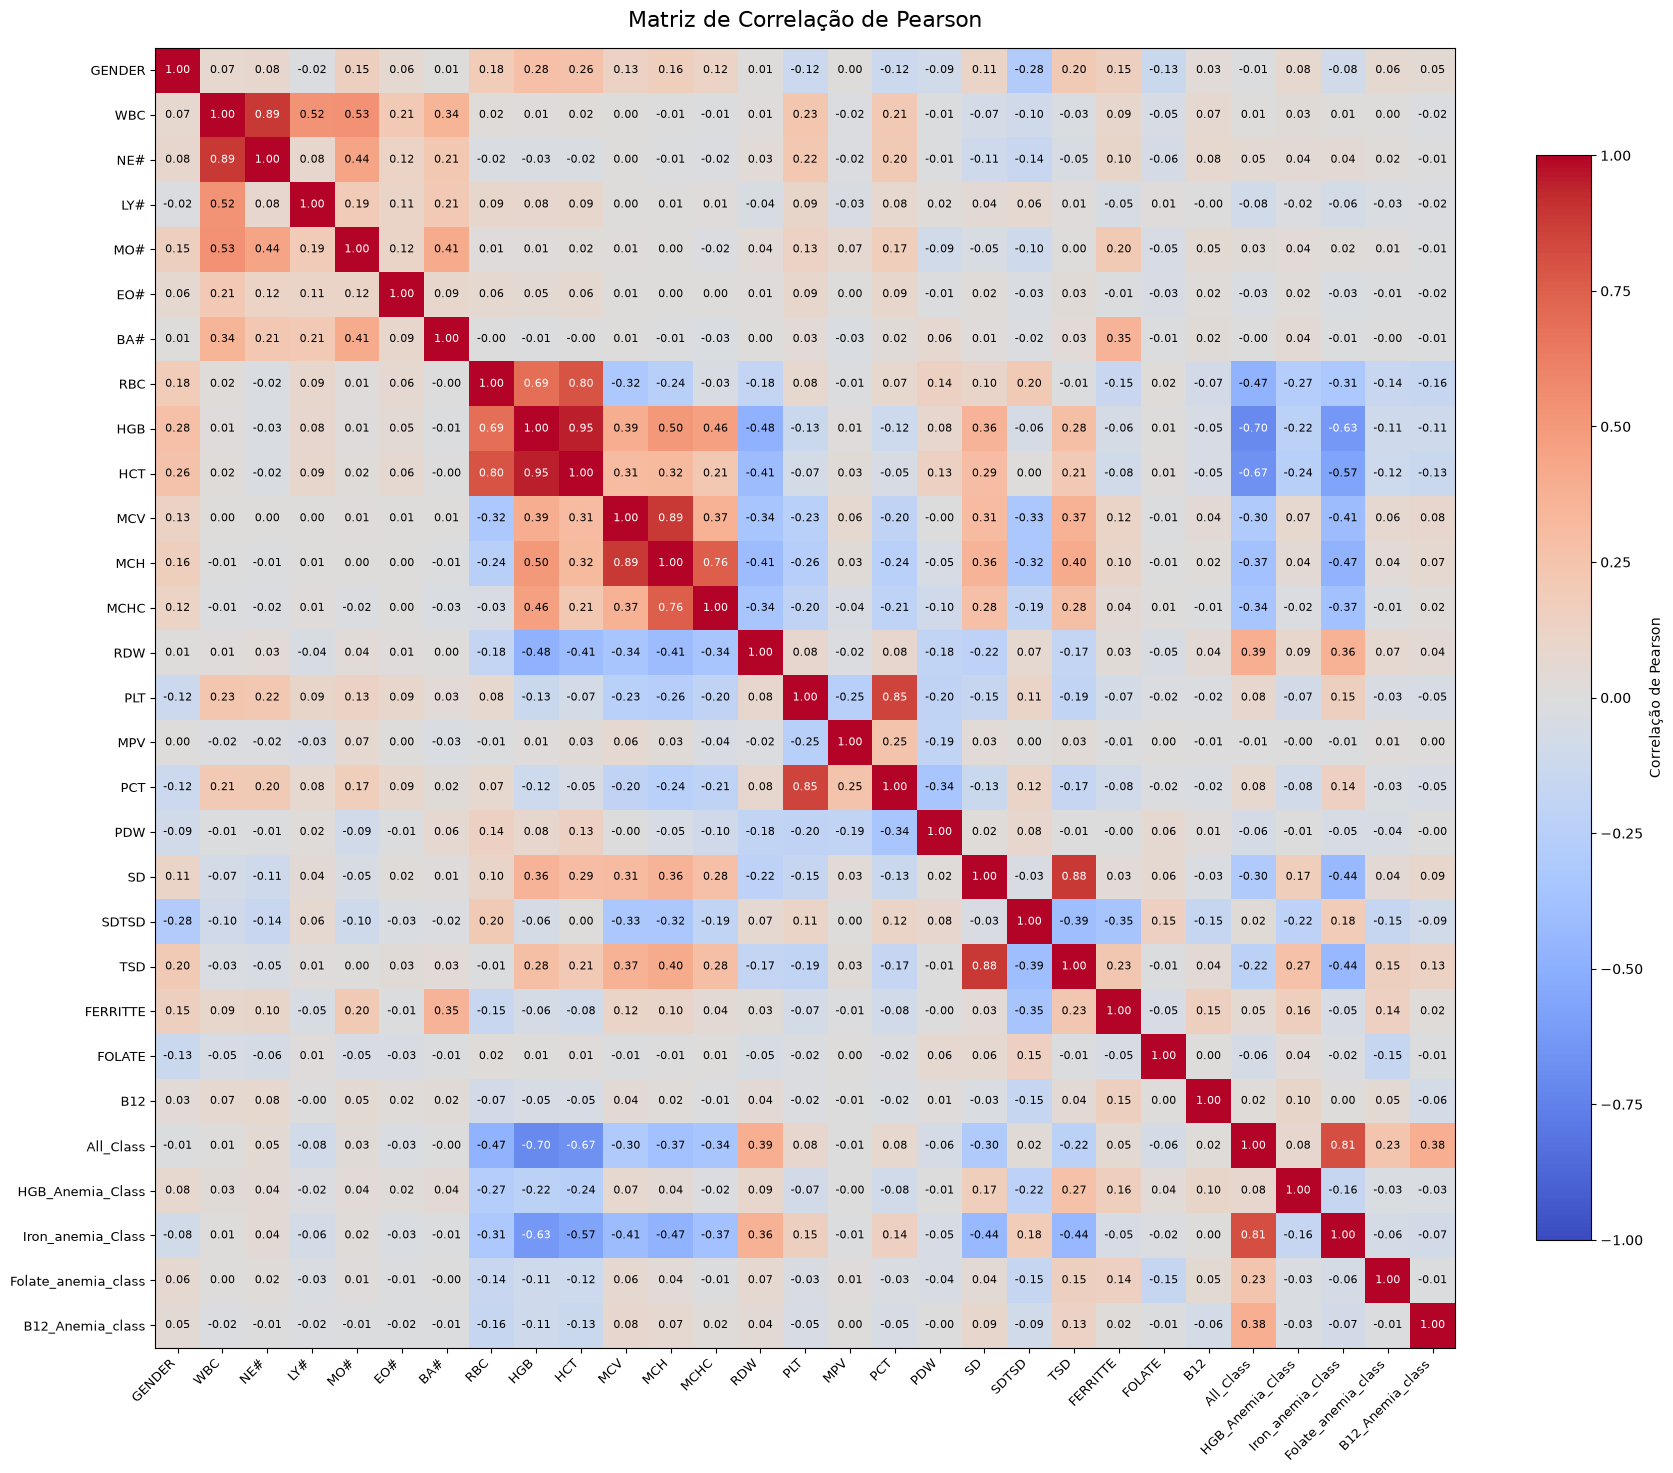

In [69]:
correlacoes = dataset.corr(numeric_only=True)
colunas_corr = correlacoes.columns.tolist()

fig, ax = plt.subplots(figsize=(18, 15))
imagem = ax.imshow(correlacoes, vmin=-1, vmax=1, cmap="coolwarm")

posicoes = np.arange(len(colunas_corr))
ax.set_xticks(posicoes, colunas_corr, rotation=45, ha="right", fontsize=9)
ax.set_yticks(posicoes, colunas_corr, fontsize=9)

for i in posicoes:
    for j in posicoes:
        valor = correlacoes.iloc[i, j]
        cor_texto = "white" if abs(valor) > 0.6 else "black"
        ax.text(
            j,
            i,
            f"{valor:.2f}",
            ha="center",
            va="center",
            fontsize=8,
            color=cor_texto,
        )

ax.set_title("Matriz de Correlação de Pearson", fontsize=16, pad=15)
fig.colorbar(imagem, ax=ax, shrink=0.8, label="Correlação de Pearson")
fig.tight_layout()
plt.show()

In [70]:
correlacoes = dataset.corr(numeric_only=True)
mascara = np.tril(np.ones(correlacoes.shape), k=-1).astype(bool)
pares_unicos = correlacoes.where(mascara).stack().reset_index()
pares_unicos.columns = ["Variável 1", "Variável 2", "Correlação (r)"]

pares_unicos["Força Absoluta"] = pares_unicos["Correlação (r)"].abs()
tabela_ordenada = (
    pares_unicos.sort_values(by="Força Absoluta", ascending=False)
    .drop(columns="Força Absoluta")
    .reset_index(drop=True)
)


@widgets.interact(
    qtd_pares=widgets.BoundedIntText(
        value=10,
        min=1,
        max=len(tabela_ordenada),
        step=1,
        description="Qtd. de pares:",
        style={"description_width": "initial"},
        layout=widgets.Layout(width="220px"),
    )
)
def exibir_pares(qtd_pares):
    print(f"Total de pares possíveis: {len(tabela_ordenada)}")
    display(tabela_ordenada.head(qtd_pares).round(3))

interactive(children=(BoundedIntText(value=10, description='Qtd. de pares:', layout=Layout(width='220px'), max…